<a href="https://colab.research.google.com/github/suryansh24-coder/Machine-Learning-Journey/blob/main/Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
import pandas as pd

X, y = make_classification(n_samples=1000, n_features=10, n_informative=5, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)
dt_acc = accuracy_score(y_test, dt_preds)
print(f"Decision Tree Accuracy: {dt_acc:.4f}")

Decision Tree Accuracy: 0.8950


In [7]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)
print(f"Random Forest Accuracy: {rf_acc:.4f}")

Random Forest Accuracy: 0.9450


In [8]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_preds_bin = [1 if p >= 0.5 else 0 for p in lr_preds]
lr_acc = accuracy_score(y_test, lr_preds_bin)
lr_mse = mean_squared_error(y_test, lr_preds)
print(f"Linear Regression (Thresholded) Accuracy: {lr_acc:.4f}")
print(f"Linear Regression MSE: {lr_mse:.4f}")

Linear Regression (Thresholded) Accuracy: 0.8300
Linear Regression MSE: 0.1355


In [9]:
comparison_data = {
    "Model": ["Decision Tree", "Random Forest", "Linear Regression"],
    "Accuracy": [dt_acc, rf_acc, lr_acc]
}
comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Model,Accuracy
0,Decision Tree,0.895
1,Random Forest,0.945
2,Linear Regression,0.830


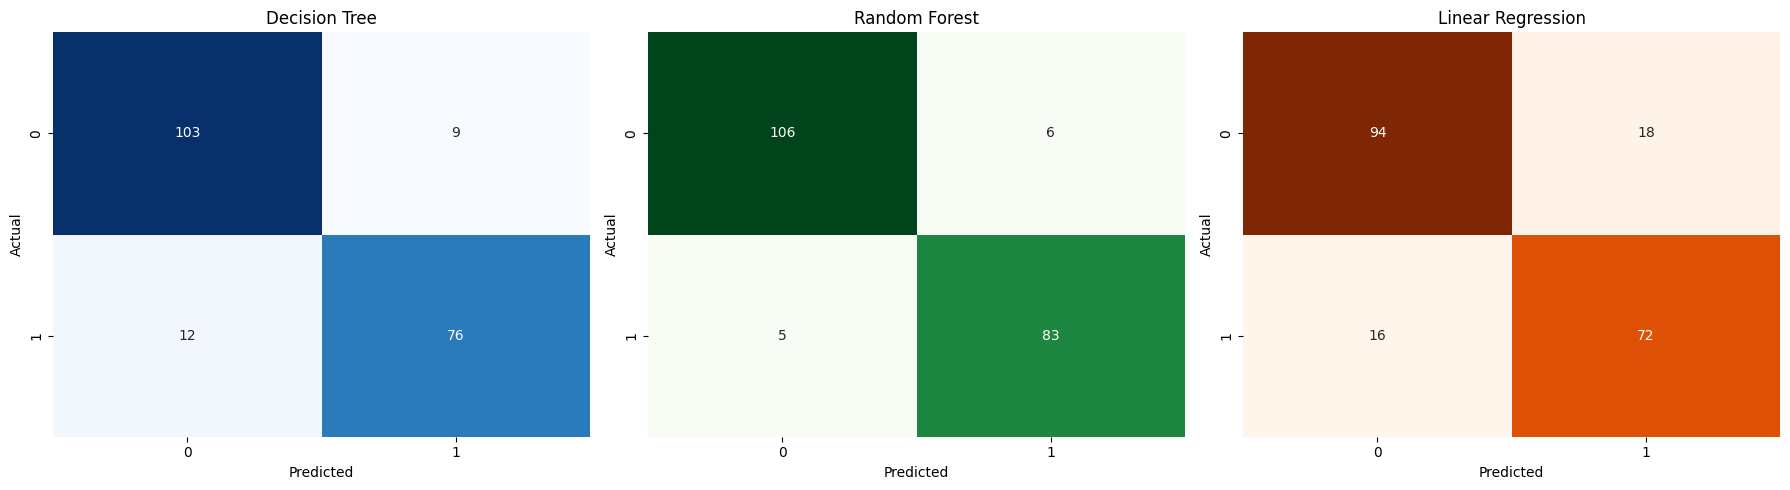

In [10]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

dt_cm = confusion_matrix(y_test, dt_preds)
rf_cm = confusion_matrix(y_test, rf_preds)
lr_cm = confusion_matrix(y_test, lr_preds_bin)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(dt_cm, annot=True, fmt="d", ax=axes[0], cmap="Blues", cbar=False)
axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(rf_cm, annot=True, fmt="d", ax=axes[1], cmap="Greens", cbar=False)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

sns.heatmap(lr_cm, annot=True, fmt="d", ax=axes[2], cmap="Oranges", cbar=False)
axes[2].set_title("Linear Regression")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [11]:
import numpy as np
from imblearn.over_sampling import SMOTE

print("Training target distribution:", np.bincount(y_train))
print("Test target distribution:", np.bincount(y_test))

Training target distribution: [385 415]
Test target distribution: [112  88]


In [12]:
dt_weighted = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dt_weighted.fit(X_train, y_train)
dt_w_preds = dt_weighted.predict(X_test)
dt_w_acc = accuracy_score(y_test, dt_w_preds)

rf_weighted = RandomForestClassifier(class_weight='balanced', random_state=42)
rf_weighted.fit(X_train, y_train)
rf_w_preds = rf_weighted.predict(X_test)
rf_w_acc = accuracy_score(y_test, rf_w_preds)

print(f"Weighted Decision Tree Accuracy: {dt_w_acc:.4f}")
print(f"Weighted Random Forest Accuracy: {rf_w_acc:.4f}")

Weighted Decision Tree Accuracy: 0.8800
Weighted Random Forest Accuracy: 0.9550


In [13]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

dt_resampled = DecisionTreeClassifier(random_state=42)
dt_resampled.fit(X_train_res, y_train_res)
dt_res_preds = dt_resampled.predict(X_test)
dt_res_acc = accuracy_score(y_test, dt_res_preds)

rf_resampled = RandomForestClassifier(random_state=42)
rf_resampled.fit(X_train_res, y_train_res)
rf_res_preds = rf_resampled.predict(X_test)
rf_res_acc = accuracy_score(y_test, rf_res_preds)

print(f"SMOTE Resampled Decision Tree Accuracy: {dt_res_acc:.4f}")
print(f"SMOTE Resampled Random Forest Accuracy: {rf_res_acc:.4f}")

SMOTE Resampled Decision Tree Accuracy: 0.8950
SMOTE Resampled Random Forest Accuracy: 0.9550


In [14]:
report_data = {
    "Method": ["Base Model", "Class Weighted", "SMOTE Resampled"],
    "Decision Tree Accuracy": [dt_acc, dt_w_acc, dt_res_acc],
    "Random Forest Accuracy": [rf_acc, rf_w_acc, rf_res_acc]
}
report_df = pd.DataFrame(report_data)
display(report_df)

,Method,Decision Tree Accuracy,Random Forest Accuracy
0,Base Model,0.895,0.945
1,Class Weighted,0.880,0.955
2,SMOTE Resampled,0.895,0.955
